In [6]:
%pip install "gymnasium[box2d]" torch numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\ASUS Vivobook\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 0. 安裝套件（首次執行時）

在 Jupyter Notebook 的新程式格執行以下命令：

```python
%pip install "gymnasium[box2d]" torch numpy matplotlib
```

若遇到 `Box2D` / `pygame` 匯入錯誤，先確認套件裝在目前 Notebook 使用的 Python 環境，安裝後重新啟動 kernel。

In [10]:
import copy
import random
from collections import deque

import gymnasium as gym
import numpy as np
import torch
#from matplotlib import pyplot as plt

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

env = gym.make("LunarLander-v3")  # 訓練時不開啟動畫，避免額外顯示負擔
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State dimension:", state_dim)    # 預期 8
print("Action dimension:", action_dim)  # 預期 4

State dimension: 8
Action dimension: 4


## 2. 建立 DQN 主網路 + Target Network

**對照 Listing 3.7：**保留 150、100 個隱藏神經元、`ReLU`、`MSELoss`、`Adam` 和 `copy.deepcopy`；把第一層輸入從 `64` 換成 `state_dim=8`。輸出仍為 4 個 Q 值，分別對應遊戲的 4 種動作。

In [ ]:
l1 = state_dim   # 原本 64，LunarLander 是 8
l2 = 150
l3 = 100
l4 = action_dim  # 仍是 4，但動作已是引擎控制

learning_rate = 1e-3
gamma = 0.99        # 長期獎勵折扣因子
epsilon = 1.0       # 初期多探索，之後逐漸降低
epsilon_min = 0.05  # 探索機率最低保留，避免完全不動作
epsilon_decay = 0.995 #讓探索機率衰減逐漸降低

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2),  # l1 輸入維度
    torch.nn.ReLU(),          # l2 第一個隱藏層的神經元數量 
    torch.nn.Linear(l2, l3),  # l3 第二個隱藏層的神經元數量
    torch.nn.ReLU(),          # l4 輸出維度
    torch.nn.Linear(l3, l4),
)
loss_fn = torch.nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

model2 = copy.deepcopy(model)                 # Target network
model2.load_state_dict(model.state_dict())  # 初始權重同步

print(model)

Sequential(
  (0): Linear(in_features=8, out_features=150, bias=True)
  (1): ReLU()
  (2): Linear(in_features=150, out_features=100, bias=True)
  (3): ReLU()
  (4): Linear(in_features=100, out_features=4, bias=True)
)


## 3. 使用 Chapter 3 Listing 3.7 的訓練架構

以下沿用老師程式的訓練流程：

1. `env.reset()` 取得 8 維狀態。
2. 用 `epsilon-greedy` 選一個離散動作（0～3）。
3. 用 `env.step(action_)` 執行，取得新狀態與 reward。
4. 將 `(state, action, reward, next_state, terminated)` 放入 replay buffer。
5. 從 buffer 隨機取 batch 更新主網路。
6. 每隔 `sync_freq` 個環境步數同步 Target Network。

**重要：**`terminated` 表示環境的終止狀態，`truncated` 表示時間限制等截斷；兩者都要結束當前回合，但 Q 值目標是否停止 bootstrap 用 `terminated` 判斷（避免把時間截斷誤當物理上的終止狀態）。

> 此版本以 CPU 也能執行為設計目標；訓練結果和速度會依電腦與參數而不同。

In [12]:
epochs = 800          # 起始訓練回合數，可在觀察結果後增加
mem_size = 50000     # LunarLander 比 Gridworld 複雜，擴大經驗池
batch_size = 64
sync_freq = 500      # 每 500 個環境步數同步目標網路
max_moves = 1000     # 每回合最多 1000 個環境步數

replay = deque(maxlen=mem_size)
losses = []
episode_rewards = []
step_count = 0

for i in range(epochs):
    state1_, info = env.reset(seed=seed if i == 0 else None)
    state1 = torch.tensor(state1_, dtype=torch.float32).reshape(1, state_dim)
    total_reward = 0.0

    for mov in range(max_moves):
        step_count += 1
        
        # E / F: Q-values + epsilon-greedy（對照老師原檔）
        if random.random() < epsilon:
            action_ = env.action_space.sample()
        else:
            with torch.no_grad():
                qval = model(state1)
                action_ = int(torch.argmax(qval, dim=1).item())

        # LunarLander 的動作就是整數 action_，不需再轉成 u/d/l/r
        state2_, reward, terminated, truncated, info = env.step(action_)
        state2 = torch.tensor(state2_, dtype=torch.float32).reshape(1, state_dim)
        total_reward += reward

        # G / H: Experience replay
        exp = (state1, action_, float(reward), state2, bool(terminated))
        replay.append(exp)
        state1 = state2

        # I ~ N: 小批次更新
        if len(replay) >= batch_size:
            minibatch = random.sample(replay, batch_size)
            state1_batch = torch.cat([s1 for (s1, a, r, s2, d) in minibatch])
            action_batch = torch.tensor([a for (s1, a, r, s2, d) in minibatch], dtype=torch.long)
            reward_batch = torch.tensor([r for (s1, a, r, s2, d) in minibatch], dtype=torch.float32)
            state2_batch = torch.cat([s2 for (s1, a, r, s2, d) in minibatch])
            done_batch = torch.tensor([d for (s1, a, r, s2, d) in minibatch], dtype=torch.float32)

            Q1 = model(state1_batch)
            with torch.no_grad():
                Q2 = model2(state2_batch)
                Y = reward_batch + gamma * (1 - done_batch) * torch.max(Q2, dim=1)[0]

            X = Q1.gather(dim=1, index=action_batch.unsqueeze(dim=1)).squeeze(dim=1)
            loss = loss_fn(X, Y)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=10.0)
            optimizer.step()
            losses.append(float(loss.item()))

        # Target network 同步（對照老師 Listing 3.7）
        if step_count % sync_freq == 0:
            model2.load_state_dict(model.state_dict())

        if terminated or truncated:
            break

    episode_rewards.append(float(total_reward))
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if (i + 1) % 20 == 0:
        recent_mean = np.mean(episode_rewards[-100:])
        print(f"Episode {i + 1:4d}/{epochs} | Reward: {total_reward:8.1f} | "
              f"Recent avg: {recent_mean:8.1f} | Epsilon: {epsilon:.3f}")

env.close()
print("Training finished.")

Episode   20/800 | Reward:   -182.8 | Recent avg:   -162.1 | Epsilon: 0.905
Episode   40/800 | Reward:   -308.0 | Recent avg:   -154.3 | Epsilon: 0.818
Episode   60/800 | Reward:   -105.1 | Recent avg:   -139.5 | Epsilon: 0.740
Episode   80/800 | Reward:    -53.9 | Recent avg:   -125.5 | Epsilon: 0.670
Episode  100/800 | Reward:    -82.8 | Recent avg:   -114.0 | Epsilon: 0.606
Episode  120/800 | Reward:    -54.3 | Recent avg:    -89.5 | Epsilon: 0.548
Episode  140/800 | Reward:    -48.9 | Recent avg:    -68.0 | Epsilon: 0.496
Episode  160/800 | Reward:    -22.8 | Recent avg:    -55.9 | Epsilon: 0.448
Episode  180/800 | Reward:     15.3 | Recent avg:    -47.4 | Epsilon: 0.406
Episode  200/800 | Reward:   -138.4 | Recent avg:    -43.8 | Epsilon: 0.367
Episode  220/800 | Reward:      2.4 | Recent avg:    -29.0 | Epsilon: 0.332
Episode  240/800 | Reward:     25.0 | Recent avg:     -4.9 | Epsilon: 0.300
Episode  260/800 | Reward:    215.7 | Recent avg:     19.7 | Epsilon: 0.272
Episode  280

## 4. 繪製訓練成果

老師原本只畫 `loss` 曲線。因為 LunarLander 的作業重點是**學會玩遊戲**，建議額外畫出每回合 `reward` 和移動平均以觀察學習成果。

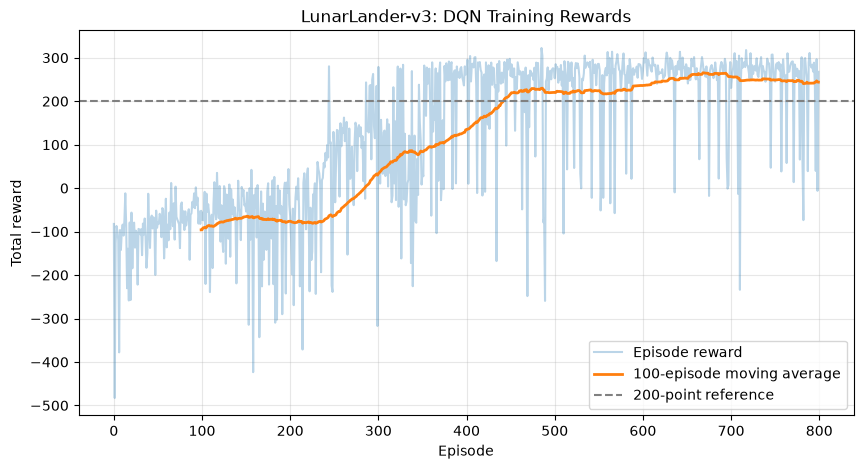

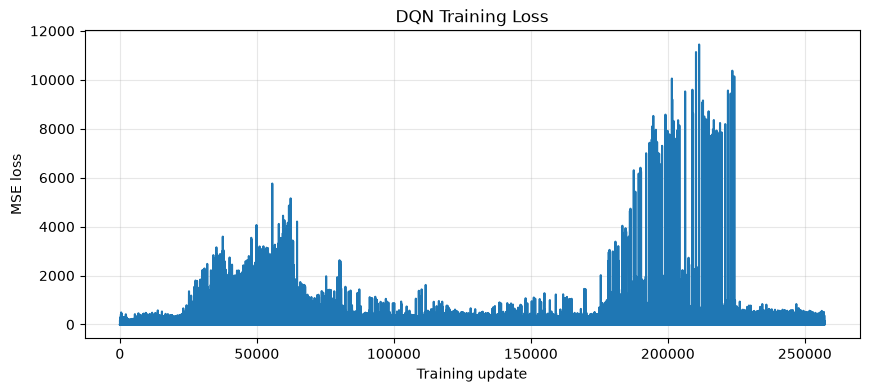

In [11]:
rewards_array = np.array(episode_rewards, dtype=float)
window = 100
moving_avg = np.convolve(rewards_array, np.ones(window) / window, mode="valid") if len(rewards_array) >= window else np.array([])

plt.figure(figsize=(10, 5))
plt.plot(rewards_array, alpha=0.3, label="Episode reward")
if len(moving_avg):
    plt.plot(np.arange(window - 1, len(rewards_array)), moving_avg,
             label=f"{window}-episode moving average", linewidth=2)
plt.axhline(200, linestyle="--", color="gray", label="200-point reference")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("LunarLander-v3: DQN Training Rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(losses)
plt.xlabel("Training update")
plt.ylabel("MSE loss")
plt.title("DQN Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 5. 測試訓練好的 AI（不再隨機探索）

不同於 Gridworld 原檔以勝率為主，這裡用多次測試的平均 reward 觀察表現。`>=200` 可當成參考，但單回合 reward 高不等於統計上表現穩定。

In [13]:
def evaluate_model(model, episodes=20):
    eval_env = gym.make("LunarLander-v3")
    scores = []
    model.eval()
    for ep in range(episodes):
        state, info = eval_env.reset(seed=1000 + ep)
        total_reward = 0.0
        while True:
            with torch.no_grad():
                state_tensor = torch.tensor(state, dtype=torch.float32).reshape(1, state_dim)
                action = int(model(state_tensor).argmax(dim=1).item())
            state, reward, terminated, truncated, info = eval_env.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        scores.append(total_reward)
    eval_env.close()
    model.train()
    return scores

test_rewards = evaluate_model(model, episodes=20)
print("Test rewards:", np.round(test_rewards, 1))
print(f"Mean reward: {np.mean(test_rewards):.2f}")
print(f"Std reward:  {np.std(test_rewards):.2f}")
print(f"Episodes with reward >= 200: {sum(score >= 200 for score in test_rewards)}/20")

Test rewards: [ 205.9  286.1  123.5  285.9  249.2  264.2  121.1  268.2   -3.6  281.
 -182.1  186.8  255.7  287.2  207.6  143.4  269.3  279.5   13.1  277.7]
Mean reward: 190.99
Std reward:  121.80
Episodes with reward >= 200: 13/20


## 6. 儲存 DQN 模型（可選）

之後要播放，不必再重新訓練，可將權重讀取至相同架構的模型。

In [16]:
torch.save(model.state_dict(), "lunarlander_dqn.pth")
print("Model weights saved to lunarlander_dqn.pth")

Model weights saved to lunarlander_dqn.pth


開始錄製 DQN 玩遊戲的畫面...
遊戲結束！
總獎勵：37.24
動畫已儲存：lunarlander_trained.gif


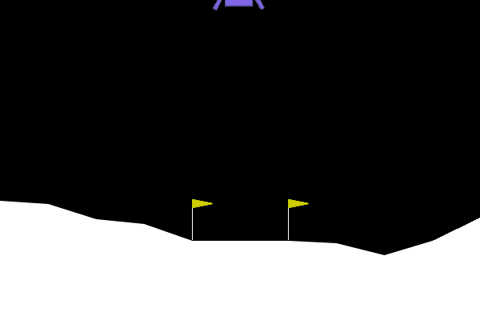

In [15]:

import gymnasium as gym
import torch
from PIL import Image as PILImage
from IPython.display import display, Image as NotebookImage

# 1. 建立可擷取遊戲畫面的環境
video_env = gym.make("LunarLander-v3", render_mode="rgb_array")

state, info = video_env.reset()
model.eval()

frames = []
total_reward = 0

print("開始錄製 DQN 玩遊戲的畫面...")

# 2. 使用訓練好的 DQN 控制太空船
for step in range(1000):

    with torch.no_grad():
        state_tensor = torch.tensor(
            state, dtype=torch.float32
        ).reshape(1, 8)

        action = int(model(state_tensor).argmax(dim=1).item())

    state, reward, terminated, truncated, info = video_env.step(action)

    total_reward += reward

    # 3. 每隔 3 步擷取遊戲畫面
    if step % 3 == 0 or terminated or truncated:
        frame = video_env.render()
        img = PILImage.fromarray(frame)
        img = img.resize((480, 320))
        frames.append(img)

    if terminated or truncated:
        break

video_env.close()

# 4. 儲存 GIF 動畫
frames[0].save(
    "lunarlander_trained.gif",
    save_all=True,
    append_images=frames[1:],
    duration=60,
    loop=0
)

# 5. 直接在 Notebook 顯示遊戲動畫
print("遊戲結束！")
print(f"總獎勵：{total_reward:.2f}")
print("動畫已儲存：lunarlander_trained.gif")

display(NotebookImage(filename="lunarlander_trained.gif"))


開始錄製 DQN 玩遊戲的畫面...
遊戲結束！
總獎勵：37.24
動畫已儲存：lunarlander_trained.gif


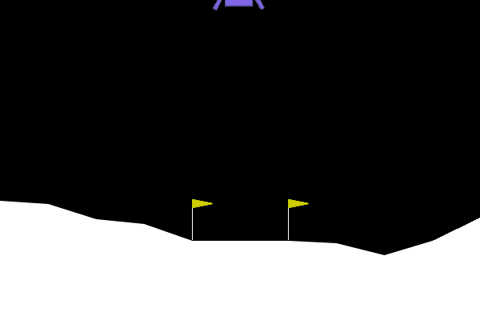

In [ ]:

import gymnasium as gym
import torch
from PIL import Image as PILImage
from IPython.display import display, Image as NotebookImage

# 1. 建立可擷取遊戲畫面的環境
video_env = gym.make("LunarLander-v3", render_mode="rgb_array")

state, info = video_env.reset()
model.eval()

frames = []
total_reward = 0

print("開始錄製 DQN 玩遊戲的畫面...")

# 2. 使用訓練好的 DQN 控制太空船
for step in range(1000):

    with torch.no_grad():
        state_tensor = torch.tensor(
            state, dtype=torch.float32
        ).reshape(1, 8)

        action = int(model(state_tensor).argmax(dim=1).item())

    state, reward, terminated, truncated, info = video_env.step(action)

    total_reward += reward

    # 3. 每隔 3 步擷取遊戲畫面
    if step % 3 == 0 or terminated or truncated:
        frame = video_env.render()
        img = PILImage.fromarray(frame)
        img = img.resize((480, 320))
        frames.append(img)

    if terminated or truncated:
        break

video_env.close()

# 4. 儲存 GIF 動畫
frames[0].save(
    "lunarlander_trained.gif",
    save_all=True,
    append_images=frames[1:],
    duration=60,
    loop=0
)

# 5. 直接在 Notebook 顯示遊戲動畫
print("遊戲結束！")
print(f"總獎勵：{total_reward:.2f}")
print("動畫已儲存：lunarlander_trained.gif")

display(NotebookImage(filename="lunarlander_trained.gif"))
